# Aerodynamics Assignment on Vortex Panel Method 
### BY: Naman Jain, SC26M013

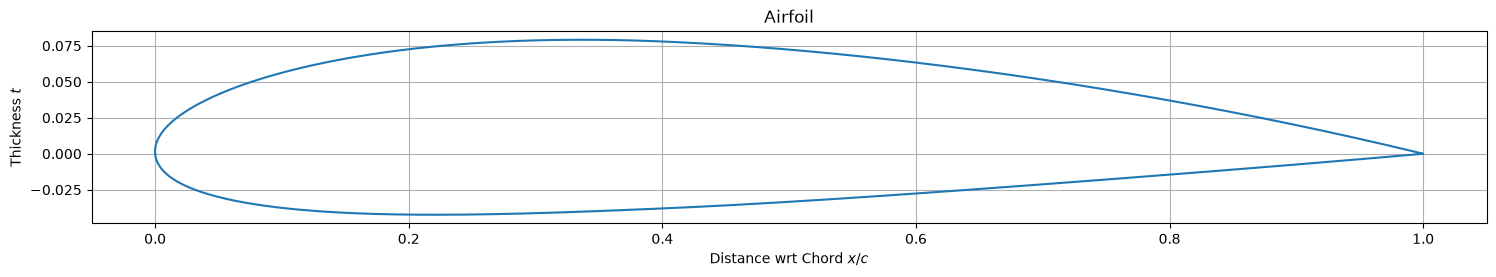

In [357]:
import numpy as np
import matplotlib.pyplot as plt

# Airfoil Plotting
a = 300 ## Number of points for plotting 
beta = np.linspace(0, np.pi, a)
x = 0.5 * (1 - np.cos(beta))

m = 2 / 100       # Maximum Camber
p = 4 / 10        # Location of Maximum Camber
t = 12 / 100     # Maximum Thickness

V_inf = 10
alpha = 0
alpha_rad = np.deg2rad(alpha)

def airfoil_generation(x, m, p, t):
    x_u = np.zeros(len(x))
    x_l = np.zeros(len(x))
    y_u = np.zeros(len(x))
    y_l = np.zeros(len(x))
    y_t = np.zeros(len(x))
    y_c = np.zeros(len(x))
    dyc_dx = np.zeros(len(x))
    theta = np.zeros(len(x))

    
    #Original Airfoil Generation 
    if p == 0:
        for i in range(len(x)):
            y_t[i] = 5*t*(0.2969*(x[i]**0.5)        # Thickness distribution
                       - 0.1260*x[i]
                       - 0.3516*(x[i]**2)
                       + 0.2843*(x[i]**3)
                       - 0.1036*(x[i]**4))
            x_u[i] = x[i]  # Upper and lower surfaces
            x_l[i] = x[i] 
            y_u[i] = y_t[i]
            y_l[i] = - y_t[i]
    else:
        for i in range(len(x)):
            y_t[i] = 5*t*(0.2969*(x[i]**0.5)        # Thickness distribution
                       - 0.1260*x[i]
                       - 0.3516*(x[i]**2)
                       + 0.2843*(x[i]**3)
                       - 0.1036*(x[i]**4))
        
            if 0 <= x[i] <= p:                      # Camber line and slope
                y_c[i] = (m / p**2) * (2*p*x[i] - x[i]**2)
                dyc_dx[i] = (2*m / p**2) * (p - x[i])
        
            elif p < x[i] <= 1:
                y_c[i] = (m / (1-p)**2) * ((1 - 2*p) + 2*p*x[i] - x[i]**2)
                dyc_dx[i] = (2*m / (1-p)**2) * (p - x[i])
                
            theta[i] = np.arctan(dyc_dx[i])         # Angle of camber line
            
            x_u[i] = x[i] - y_t[i]*np.sin(theta[i]) # Upper and lower surfaces
            x_l[i] = x[i] + y_t[i]*np.sin(theta[i])
            y_u[i] = y_c[i] + y_t[i]*np.cos(theta[i])
            y_l[i] = y_c[i] - y_t[i]*np.cos(theta[i])

    x_u[0], y_u[0] = 0.0, 0.0
    x_l[0], y_l[0] = 0.0, 0.0

    x_u[-1], y_u[-1] = 1.0, 0.0
    x_l[-1], y_l[-1] = 1.0, 0.0
    
    # Combine upper and lower surfaces
        # Combine surfaces: LE -> Upper TE -> Lower LE -> LE
    x_full = np.concatenate((x_u, x_l[-2:0:-1], [x_l[0]]))
    y_full = np.concatenate((y_u, y_l[-2:0:-1], [y_l[0]]))

    return x_full, y_full
    
    

a = airfoil_generation(x, m, p, t)

plt.figure(figsize=(18, 2.5))
plt.plot(a[0], a[1])
plt.xlabel("Distance wrt Chord $x/c$")
plt.ylabel("Thickness $t$")
plt.title("Airfoil")
plt.grid(True)
plt.show()


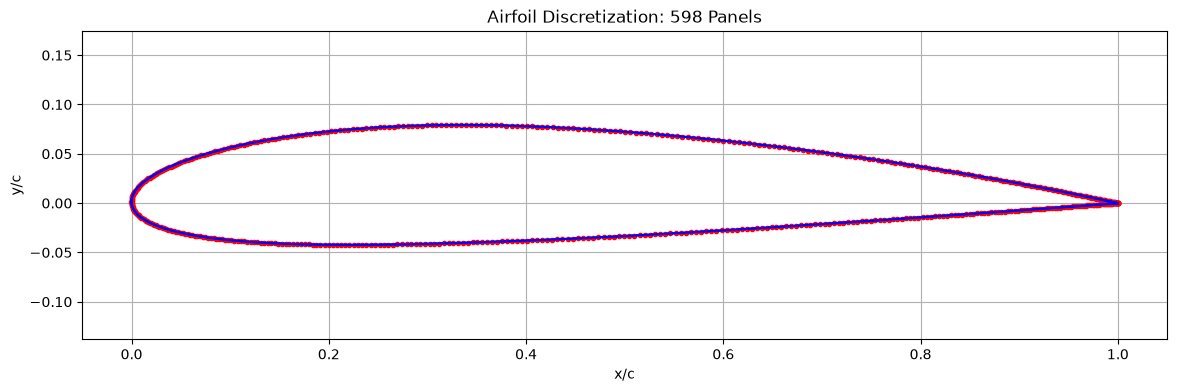

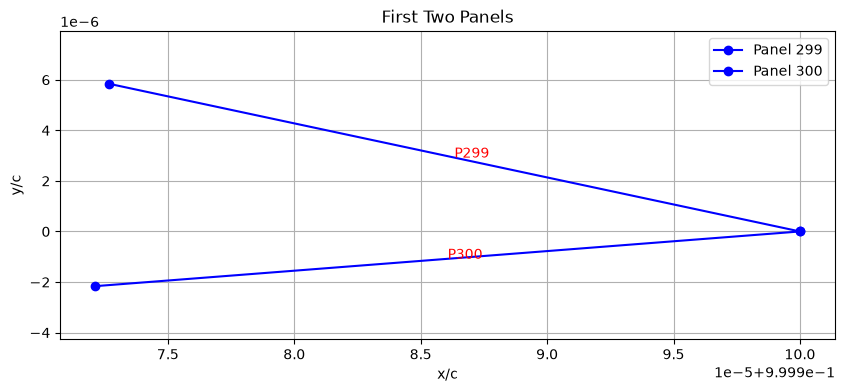

In [358]:
def panel_gen(x, y, V_inf, alpha_rad):
    x1 = x[:-1]
    y1 = y[:-1]
    x2 = x[1:]
    y2 = y[1:]

    N = len(x) - 1
    l = np.sqrt((x2 - x1)**2 + (y2 - y1)**2)
    
    x_c = (x1 + x2)/2
    y_c1 = (y1 + y2)/2

    theta_p = np.arctan2((y2 - y1),(x2 - x1))
    theta_p = np.mod(theta_p, 2 * np.pi)

    theta_final = theta_p + np.pi / 2
    beta  = theta_final - alpha_rad

    V_normal = V_inf * np.cos(beta)
    V_tangent = V_inf * np.sin(beta)
    
    return N, l, x_c, y_c1, theta_p, x1, x2, y1, y2, V_normal, V_tangent 

x_airfoil, y_airfoil = airfoil_generation(x, m, p, t)
N, l, x_c, y_c1, theta_p, x1, x2, y1, y2, V_normal, V_tangent = panel_gen(x_airfoil, y_airfoil, V_inf, alpha_rad)

# Plot panels and collocation points
plt.figure(figsize=(14, 4))
plt.plot(x_airfoil, y_airfoil, 'k-', linewidth=1)
plt.plot(x_c, y_c1, 'ro', markersize=3)

for i in range(N):
    plt.plot([x1[i], x2[i]], [y1[i], y2[i]], 'b-')
plt.axis('equal')
plt.xlabel('x/c')
plt.ylabel('y/c')
plt.title(f'Airfoil Discretization: {N} Panels')
plt.grid(True)
plt.show()

plt.figure(figsize=(10, 4))

for i in range(N//2 -1, N//2+1):
    plt.plot(
        [x1[i], x2[i]],
        [y1[i], y2[i]],
        'b-o',
        label=f'Panel {i+1}'
    )

    plt.text(x_c[i], y_c1[i], f'P{i+1}', color='red')

plt.axis('equal')
plt.xlabel('x/c')
plt.ylabel('y/c')
plt.title('First Two Panels')
plt.grid(True)
plt.legend()
plt.show()

In [359]:
def JK_matrix(N, l, x_c, y_c1, theta_p, x1, x2, y1, y2):
    J = np.zeros((N,N))
    K = np.zeros((N,N))
    
    for i in range(N):
        normal_vector0 = np.array([ - np.sin(theta_p[i]), np.cos(theta_p[i])])
        tangent_vector0 = np.array([np.cos(theta_p[i]), np.sin(theta_p[i])])
        
        for j in range(N):

            if i == j:
                continue
                
            A_j = np.array([x1[j], y1[j]])
            P_i = np.array([x_c[i], y_c1[i]])

            tangent_vector1 = np.array([np.cos(theta_p[j]), np.sin(theta_p[j])])
            normal_vector1 = np.array([- np.sin(theta_p[j]), np.cos(theta_p[j])])

            A = - np.dot((P_i - A_j), tangent_vector1)
            B = (P_i[0] - A_j[0])**2 + (P_i[1] - A_j[1])**2
            Cn = - np.cos(theta_p[i] - theta_p[j])
            Ct = np.sin(theta_p[j] - theta_p[i])
            Dn = np.dot((P_i - A_j), tangent_vector0)
            Dt = (P_i[0] - A_j[0]) * np.sin(theta_p[i]) - (P_i[1] - A_j[1]) * np.cos(theta_p[i])
            E2 = B - A**2
            if E2 <= 1e-14:
                continue
            E = np.sqrt(E2)
            if E <= 1e-14:
                continue
                
            log_term = np.log((l[j]**2 + 2.0*A*l[j] + B) / B)
            angle_term = (np.arctan2(l[j] + A, E) - np.arctan2(A, E))
            
            J[i, j] = (0.5 * Cn * log_term + ((Dn - A*Cn) / E) * angle_term)
            K[i,j] = (0.5 * Ct * log_term + ((Dt - A*Ct) / E) * angle_term)

    return J, K

J, K = JK_matrix(N, l, x_c, y_c1, theta_p, x1, x2, y1, y2)

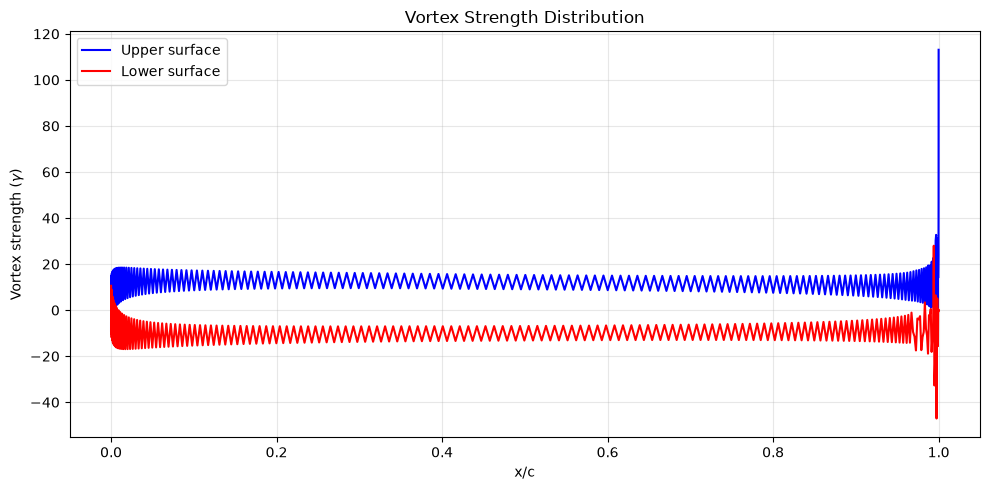

In [360]:
def vortex_panel_method_0(N, V_normal, alpha, J, theta_final):

    A = np.zeros((N,N))
    b = np.zeros(N)

    A[:,:] = - J[:,:]
    b[:] = -2 * np.pi * V_normal[:]

    #Kutta Condition
    A[N//2, :] = 0.0
    A[N//2, N//2 + 1] = 1.0
    A[N//2, N//2 ] = 1.0

    b[N//2] = 0.0

    # Solve for vortex strengths
    gamma = np.linalg.solve(A, b)

    return gamma, A, b
    
gamma, A, b = vortex_panel_method_0(N, V_normal, alpha, J, theta_p)

plt.figure(figsize=(10, 5))
plt.plot(x_c[:N//2], gamma[:N//2 ], 'b-', label='Upper surface')
plt.plot(x_c[N//2 +1:], gamma[N//2 + 1:], 'r-', label='Lower surface')
plt.xlabel('x/c')
plt.ylabel('Vortex strength ($\gamma$)')
plt.title('Vortex Strength Distribution')
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

The Coefficient of lift generated at 0 degrees by NACA 2412 is: 0.45505133775767775


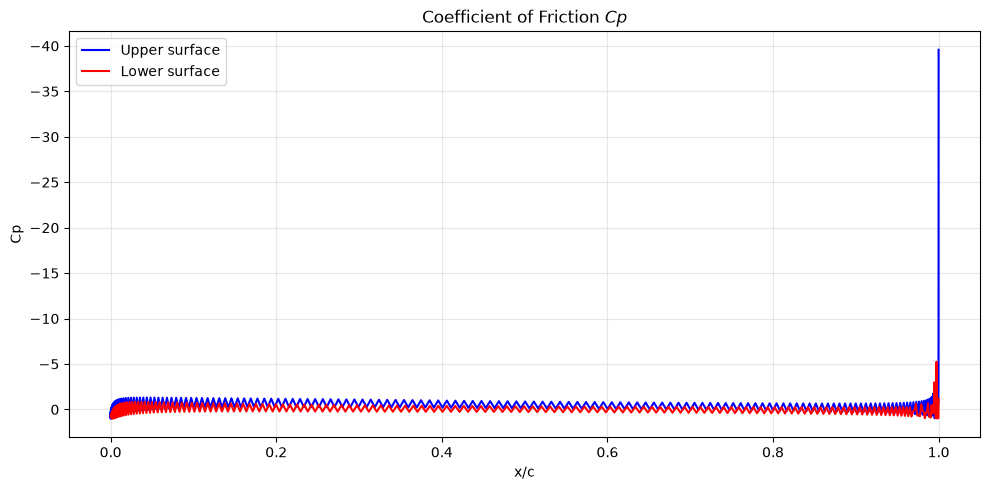

In [368]:
def Cp(N, K, V_tangent, gamma, V_inf):
    Vt = np.zeros(N)

    for i in range(N):
        induced_v = 0.0
        for j in range(N):
            induced_v = induced_v - gamma[j] * K[i, j] / (2*np.pi)
        Vt[i] = (V_tangent[i] + induced_v + gamma[i]/2)

    Cp = 1 - (Vt / V_inf)**2

    return Cp 

def lift_coeff(N, V_inf, gamma, l):
    circulation = np.zeros(N)
    for i in range(N):
        circulation[i] = gamma[i]*l[i]

    total_circulation = np.sum(circulation)
    Cl = 2 * total_circulation / V_inf

    return Cl

Cl = lift_coeff(N, V_inf, gamma, l)
Cp = Cp(N, K, V_tangent, gamma, V_inf)
print(f"The Coefficient of lift generated at {alpha} degrees by NACA {int(m*100)}{int(p*10)}{int(t*100)} is: {Cl}")

plt.figure(figsize=(10, 5))
plt.plot(x_c[:N//2], Cp[:N//2 ], 'b-', label='Upper surface')
plt.plot(x_c[N//2 +1:], Cp[N//2 + 1:], 'r-', label='Lower surface')
plt.xlabel('x/c')
plt.ylabel('Cp')
plt.title('Coefficient of Friction $Cp$')
plt.gca().invert_yaxis()
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()